# Chapter 4 · Detection

*Book 27 · Deep Learning on Images & Signals · Shelf VII*

**Builds on:** [Chapter 3](03-geometry-and-distortion.ipynb) (homographies, blur) and
[Chapter 2](02-classical-image-processing.ipynb) (thresholds, sharpening).
**You will:** find a QR code's three finder patterns from contours alone, decode it with OpenCV,
measure the decode rate across photo qualities, and rescue the soft photos with preprocessing --
then see where no preprocessing can help.

Detection answers *where*; decoding answers *what*. For a QR code, *where* is marked on purpose:
three nested squares in three corners.

In [1]:
import cv2
import matplotlib.pyplot as plt
import pandas as pd
import qrcode

from ds_toolbox import qrbills as qb
from ds_toolbox import viz

viz.use_style()
bills = qb.generate_bills(12, seed=4)
img = qb.render(bills[0])

## Finder patterns from contours

A finder pattern is a black square inside a white square inside a black square. After
binarising, its outline is a contour with *two* contours nested inside it -- a pattern almost
nothing else on the bill has. `cv2.findContours` with `RETR_TREE` returns that nesting.

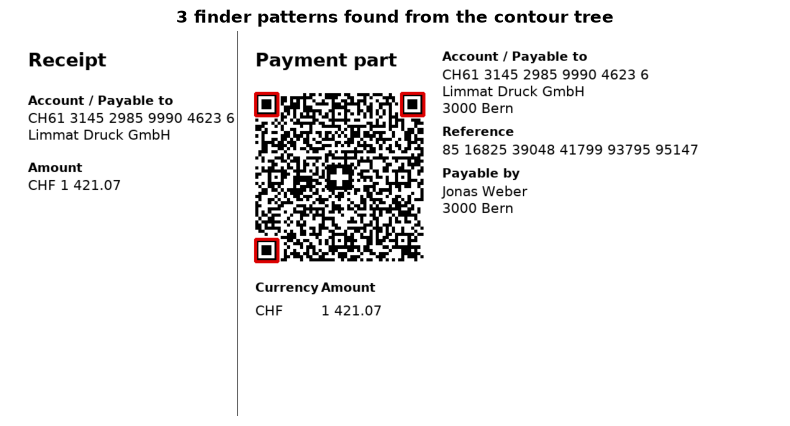

In [2]:
grey = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
_, binary = cv2.threshold(grey, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
contours, hierarchy = cv2.findContours(binary, cv2.RETR_TREE, cv2.CHAIN_APPROX_SIMPLE)
hierarchy = hierarchy[0]

def depth_below(i):
    d, child = 0, hierarchy[i][2]
    while child != -1:
        d, child = d + 1, hierarchy[child][2]
    return d

finders = []
for i, c in enumerate(contours):
    x, y, cw, ch = cv2.boundingRect(c)
    if depth_below(i) >= 2 and 0.8 < cw / ch < 1.25 and cw > 20:
        finders.append((x, y, cw, ch))
finders = sorted(set(finders), key=lambda b: -b[2])[:3]
shown = img.copy()
for x, y, cw, ch in finders:
    cv2.rectangle(shown, (x, y), (x + cw, y + ch), (220, 0, 0), 4)
plt.figure(figsize=(10, 5))
plt.imshow(shown)
plt.axis("off")
plt.title(f"{len(finders)} finder patterns found from the contour tree");

Three corners of a square are enough to know where the code is, how large it is and how it is
rotated. A production decoder goes on to sample the module grid and correct errors -- OpenCV's
does all of that in one call.

In [3]:
detector = cv2.QRCodeDetectorAruco()
payload, points, _ = detector.detectAndDecode(img)
print("decoded:", payload == bills[0].qr_payload())
print(qb.parse_payload(payload))

decoded: True
{'iban': 'CH6131452985999046236', 'creditor_name': 'Limmat Druck GmbH', 'creditor_city': 'Bern', 'amount': '1421.07', 'reference': '851682539048417999379595147'}


## How often does it decode?

Twelve bills at each of the five qualities, first as photographed, then after the
chapter-2 preprocessing in `qrbills.sharpen_for_qr`: upscale 2x, unsharp-mask, adaptive
threshold.

In [4]:
rows = []
for k, b in enumerate(bills):
    clean = qb.render(b)
    for level in qb.QUALITY_LEVELS:
        photo = qb.distort(clean, level, seed=100 * k + level)
        rows.append({"level": level,
                     "as photographed": detector.detectAndDecode(photo)[0] == b.qr_payload(),
                     "sharpened": detector.detectAndDecode(qb.sharpen_for_qr(photo))[0] == b.qr_payload()})
rate = pd.DataFrame(rows).groupby("level").mean()
rate.index = [f"{k} · {qb.QUALITY_LEVELS[k]}" for k in rate.index]
(rate * 100).round(0)

,as photographed,sharpened
0 · flat scan,100.0,100.0
1 · good photo,83.0,100.0
2 · handheld photo,8.0,92.0
3 · far and blurred,0.0,0.0
4 · unreadable,0.0,0.0


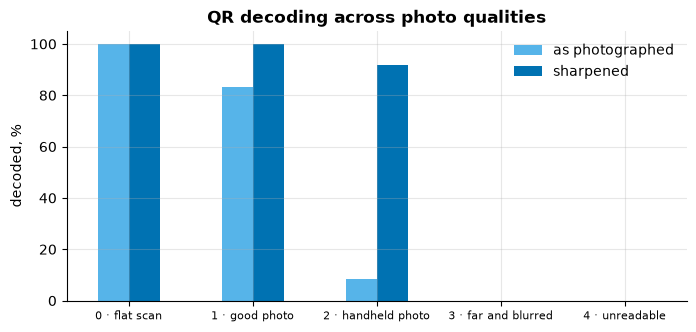

In [5]:
ax = (rate * 100).plot.bar(figsize=(8, 3.5), rot=0, color=[viz.PALETTE[5], viz.PALETTE[0]])
ax.set(ylabel="decoded, %", title="QR decoding across photo qualities")
ax.tick_params(axis="x", labelsize=8);

## Where preprocessing stops helping

A decoder has to tell each **module** -- one black or white cell of the code -- from its
neighbours. How many pixels does one module get at each quality?

In [6]:
version_modules = None
for v in range(1, 41):          # the smallest QR version this payload fits
    q = qrcode.QRCode(version=v, error_correction=qrcode.constants.ERROR_CORRECT_M, border=0)
    q.add_data(bills[0].qr_payload())
    try:
        q.make(fit=False)
        version_modules = (v, 17 + 4 * v)
        break
    except Exception:          # the payload does not fit this version
        continue
v, modules = version_modules
side_px = 46 * 150 / 25.4
for level in qb.QUALITY_LEVELS:
    scale = [1, 1, 1, 0.6, 0.45][level]
    blur = [0, 1.0, 1.6, 2.4, 3.2][level]
    print(f"level {level}: {side_px * scale / modules:4.1f} px per module, "
          f"blur {2.355 * blur:3.1f} px wide (FWHM)")
print(f"(QR version {v}: {modules} x {modules} modules)")

level 0:  5.1 px per module, blur 0.0 px wide (FWHM)
level 1:  5.1 px per module, blur 2.4 px wide (FWHM)
level 2:  5.1 px per module, blur 3.8 px wide (FWHM)
level 3:  3.1 px per module, blur 5.7 px wide (FWHM)
level 4:  2.3 px per module, blur 7.5 px wide (FWHM)
(QR version 9: 53 x 53 modules)


Once the blur is as wide as a module (its full width at half maximum, about 2.4 sigma), black
and white cells merge into grey and the information is gone, not hidden; sharpening cannot invent it back. That is the moment to read
the printed text instead -- chapter 6.

## What to remember

- Detection finds *where*; a QR code makes that easy with its finder patterns.
- Preprocessing rescues codes that are soft, not codes whose modules have merged.
- Measure the resolution budget (pixels per module) before blaming the decoder.

## Exercises

1. Use the three finder centres to estimate the code's rotation angle. Compare with `distort`.
2. Try `cv2.QRCodeDetector()` (without ArUco) on the sharpened images. Which is more robust?
3. At which downscale factor does level 2 stop decoding, with the blur held fixed?

**Next:** [Chapter 5 · CNNs on images](05-cnns-on-images.ipynb)